In [58]:
import squidpy as sq
import scanpy as sp
import pandas as pd
import numpy as np
from matplotlib import rcParams
import matplotlib.pyplot as plt
import os
import numpy as np
os.chdir('/home/haider/Squidpy_Spatial_analysis')
import spatialdata as sd
from spatialdata_io import xenium
from napari_spatialdata import Interactive
import seaborn as sns
from spatialdata import polygon_query
import matplotlib.pyplot as plt
# from nico import Annotations as sann
# from nico import Interactions as sint
# from nico import Covariations as scov

In [21]:
# Load and prepare anndata object
# Add the metadata column
def generate_anndata(obj, meta, name):
    obj.obs=meta
    df=meta[['x_centroid', 'y_centroid']]
    df=df.to_numpy()
    # Add spatial co-ordinates to the object
    obj.obsm["spatial"]=df
    # Change cell_ids
    #obj.obs['cell_id']=obj.obs['cell_id'].apply(lambda x: '{}_'.format(name) + x)
    # Filter samples based on seurat_co-ordinates
    obj=obj[obj.obs['cell_id'].isin(list(seurat_cord['cell_id']))]
    return obj


In [22]:
# Seurat Cluster co-ordinates
seurat_cord = pd.read_csv('/home/haider/Squidpy_Spatial_analysis/seurat_cord.csv')
seurat_cord.rename(columns={'X': 'cell_id'}, inplace=True)

# BOS samples
BOS11A = sp.read_10x_h5('/home/haider/Squidpy_Spatial_analysis/BOS/BOS11A/cell_feature_matrix.h5')
meta_data = pd.read_csv('/home/haider/Squidpy_Spatial_analysis/BOS/BOS11A/cells.csv')
BOS11A=generate_anndata(BOS11A, meta_data, 'BOS11A')

BOS12D = sp.read_10x_h5('/home/haider/Squidpy_Spatial_analysis/BOS/BOS12D/cell_feature_matrix.h5')
meta_data = pd.read_csv('/home/haider/Squidpy_Spatial_analysis/BOS/BOS12D/cells.csv')
BOS12D=generate_anndata(BOS12D, meta_data, 'BOS12D')

BOS13E = sp.read_10x_h5('/home/haider/Squidpy_Spatial_analysis/BOS/BOS13E/cell_feature_matrix.h5')
meta_data = pd.read_csv('/home/haider/Squidpy_Spatial_analysis/BOS/BOS13E/cells.csv')
BOS13E=generate_anndata(BOS13E, meta_data, 'BOS13E')


#Asthma
MTS21A = sp.read_10x_h5('/home/haider/Squidpy_Spatial_analysis/BOS/MTS21A/cell_feature_matrix.h5')
meta_data = pd.read_csv('/home/haider/Squidpy_Spatial_analysis/BOS/MTS21A/cells.csv')
MTS21A=generate_anndata(MTS21A, meta_data, 'MTS21A')

MTS27E = sp.read_10x_h5('/home/haider/Squidpy_Spatial_analysis/BOS/MTS27E/cell_feature_matrix.h5')
meta_data = pd.read_csv('/home/haider/Squidpy_Spatial_analysis/BOS/MTS27E/cells.csv')
MTS27E=generate_anndata(MTS27E, meta_data, 'MTS27E')

MTS48B = sp.read_10x_h5('/home/haider/Squidpy_Spatial_analysis/BOS/MTS48B/cell_feature_matrix.h5')
meta_data = pd.read_csv('/home/haider/Squidpy_Spatial_analysis/BOS/MTS48B/cells.csv')
MTS48B=generate_anndata(MTS48B, meta_data, 'MTS48B')


#Healthy control
ID6 = sp.read_10x_h5('/home/haider/Squidpy_Spatial_analysis/HC/ID6/cell_feature_matrix.h5')
meta_data = pd.read_csv('/home/haider/Squidpy_Spatial_analysis/HC/ID6/cells.csv')
ID6=generate_anndata(ID6, meta_data, 'ID6')

MTS12D = sp.read_10x_h5('/home/haider/Squidpy_Spatial_analysis/HC/MTS12D/cell_feature_matrix.h5')
meta_data = pd.read_csv('/home/haider/Squidpy_Spatial_analysis/HC/MTS12D/cells.csv')
MTS12D=generate_anndata(MTS12D, meta_data, 'MTS12D')

MTS29E = sp.read_10x_h5('/home/haider/Squidpy_Spatial_analysis/HC/MTS29E/cell_feature_matrix.h5')
meta_data = pd.read_csv('/home/haider/Squidpy_Spatial_analysis/HC/MTS29E/cells.csv')
MTS29E=generate_anndata(MTS29E, meta_data, 'MTS29E')

MTS38D = sp.read_10x_h5('/home/haider/Squidpy_Spatial_analysis/HC/MTS38D/cell_feature_matrix.h5')
meta_data = pd.read_csv('/home/haider/Squidpy_Spatial_analysis/HC/MTS38D/cells.csv')
MTS38D=generate_anndata(MTS38D, meta_data, 'MTS38D')

MTS43D = sp.read_10x_h5('/home/haider/Squidpy_Spatial_analysis/HC/MTS43D/cell_feature_matrix.h5')
meta_data = pd.read_csv('/home/haider/Squidpy_Spatial_analysis/HC/MTS43D/cells.csv')
MTS43D=generate_anndata(MTS43D, meta_data, 'MTS43D')

MTS7D = sp.read_10x_h5('/home/haider/Squidpy_Spatial_analysis/HC/MTS7D/cell_feature_matrix.h5')
meta_data = pd.read_csv('/home/haider/Squidpy_Spatial_analysis/HC/MTS7D/cells.csv')
MTS7D=generate_anndata(MTS7D, meta_data, 'MTS7D')


#CF
CF19 = sp.read_10x_h5('/home/haider/Squidpy_Spatial_analysis/CF/CF19/cell_feature_matrix.h5')
meta_data = pd.read_csv('/home/haider/Squidpy_Spatial_analysis/CF/CF19/cells.csv')
CF19=generate_anndata(CF19, meta_data, 'CF19')

CF20 = sp.read_10x_h5('/home/haider/Squidpy_Spatial_analysis/CF/CF20/cell_feature_matrix.h5')
meta_data = pd.read_csv('/home/haider/Squidpy_Spatial_analysis/CF/CF20/cells.csv')
CF20=generate_anndata(CF20, meta_data, 'CF20')

CF27 = sp.read_10x_h5('/home/haider/Squidpy_Spatial_analysis/CF/CF27/cell_feature_matrix.h5')
meta_data = pd.read_csv('/home/haider/Squidpy_Spatial_analysis/CF/CF27/cells.csv')
CF27=generate_anndata(CF27, meta_data, 'CF27')

CF35 = sp.read_10x_h5('/home/haider/Squidpy_Spatial_analysis/CF/CF35/cell_feature_matrix.h5')
meta_data = pd.read_csv('/home/haider/Squidpy_Spatial_analysis/CF/CF35/cells.csv')
CF35=generate_anndata(CF35, meta_data, 'CF35')

CF40 = sp.read_10x_h5('/home/haider/Squidpy_Spatial_analysis/CF/CF40/cell_feature_matrix.h5')
meta_data = pd.read_csv('/home/haider/Squidpy_Spatial_analysis/CF/CF40/cells.csv')
CF40=generate_anndata(CF40, meta_data, 'CF40')


#COPD
C48A = sp.read_10x_h5('/home/haider/Squidpy_Spatial_analysis/COPD/C48A/cell_feature_matrix.h5')
meta_data = pd.read_csv('/home/haider/Squidpy_Spatial_analysis/COPD/C48A/cells.csv')
C48A=generate_anndata(C48A, meta_data, 'C48A')

C50C = sp.read_10x_h5('/home/haider/Squidpy_Spatial_analysis/COPD/C50C/cell_feature_matrix.h5')
meta_data = pd.read_csv('/home/haider/Squidpy_Spatial_analysis/COPD/C50C/cells.csv')
C50C=generate_anndata(C50C, meta_data, 'C50C')

C51E = sp.read_10x_h5('/home/haider/Squidpy_Spatial_analysis/COPD/C51E/cell_feature_matrix.h5')
meta_data = pd.read_csv('/home/haider/Squidpy_Spatial_analysis/COPD/C51E/cells.csv')
C51E=generate_anndata(C51E, meta_data, 'C51E')

C52E = sp.read_10x_h5('/home/haider/Squidpy_Spatial_analysis/COPD/C52E/cell_feature_matrix.h5')
meta_data = pd.read_csv('/home/haider/Squidpy_Spatial_analysis/COPD/C52E/cells.csv')
C52E=generate_anndata(C52E, meta_data, 'C52E')

C56E = sp.read_10x_h5('/home/haider/Squidpy_Spatial_analysis/COPD/C56E/cell_feature_matrix.h5')
meta_data = pd.read_csv('/home/haider/Squidpy_Spatial_analysis/COPD/C56E/cells.csv')
C56E=generate_anndata(C56E, meta_data, 'C56E')

In [160]:
# Merge All objects
lis=[ID6,MTS7D, MTS12D, MTS29E, MTS38D, MTS43D, C48A,C50C,C51E ,C52E, C56E, CF19, CF20, CF27, CF35, CF40, BOS11A, BOS12D, BOS13E, MTS21A, MTS48B, MTS27E]
final_merged=sp.concat(lis, join='outer')
final_merged

/home/haider/miniconda3/lib/python3.12/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/home/haider/miniconda3/lib/python3.12/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


AnnData object with n_obs × n_vars = 2091420 × 389
    obs: 'cell_id', 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method'
    obsm: 'spatial'

In [161]:
final_merged.obs.set_index('cell_id', inplace=True)
final_merged.obs['duplicates'] = final_merged.obs.index.duplicated()
final_merged=final_merged[final_merged.obs['duplicates']==False]
final_merged


View of AnnData object with n_obs × n_vars = 2090869 × 389
    obs: 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'duplicates'
    obsm: 'spatial'

In [173]:
final_merged.obs['Cell_Class'],final_merged.obs['ID'], final_merged.obs['subtype'],final_merged.obs['Group'], final_merged.obs['seurat_clusters'] =list(seurat_cord['Cell_Class']), list(seurat_cord['ID']), list(seurat_cord['subtype']), list(seurat_cord['Group']), list(seurat_cord['seurat_clusters'])

In [158]:
final_merged.write_h5ad('/home/haider/Squidpy_Spatial_analysis/final_merged')

In [275]:
# Add a new category named regions
# final_merged=sp.read_h5ad('final_merged')
# final_merged.obs['region']=final_merged.obs['subtype']
lis=['AT1', 'AT2', 'AT2_EC_DB', 'DMBT1+_AT2', 'aCap', 'gCap','FCN3+_EC']
lis2=['Basal', 'Cil', 'Sec', 'Gob', 'SMC', 'DES+_SMC', 'PLA2G2A+_FB']
lis3=['TkC', 'ThC', 'cDC', 'Mono/Macs', 'AM', 'Mast', 'GB', 'BC', 'PMN',"Perivasc_macs", "CXCL+_Immune"]
lis4=['APOD+_FB','FB','Peri', 'LEC']
new_order=lis+lis2+lis3+lis4
# final_merged.obs['region'] = np.where(final_merged.obs['region'].isin(lis), 'Alveolar', final_merged.obs['region'])
# final_merged.obs['region'] = np.where(final_merged.obs['region'].isin(lis2), 'Vascular', final_merged.obs['region'])
# final_merged.obs['region'] = np.where(final_merged.obs['region'].isin(lis3), 'Immune', final_merged.obs['region'])
# final_merged.obs['region'] = np.where(final_merged.obs['region'].isin(lis4), 'Mesenchyme', final_merged.obs['region'])
# final_merged.obs['region'] = final_merged.obs['region'].astype('category')


In [15]:
#ann=MTS12D_zarr.tables['table']
ann[ann.obs['cell_id'].isin(['MTS12D'])]
ann.obs

,transcript_counts,control_probe_counts,genomic_control_counts,control_codeword_counts,unassigned_codeword_counts,deprecated_codeword_counts,total_counts,cell_area,nucleus_area,nucleus_count,segmentation_method,region,z_level,cell_labels,duplicates
cell_id,,,,,,,,,,,,,,,
aaaalidn-1,75,1,0,0,0,0,76,40.414845,28.222657,1.0,Segmented by boundary stain (ATP1A1+CD45+E-Cad...,cell_circles,0.0,1,False
aaaapknf-1,0,0,0,0,0,0,0,36.982970,NaN,0.0,Segmented by boundary stain (ATP1A1+CD45+E-Cad...,cell_circles,0.0,2,False
aaabfoil-1,384,0,0,0,0,0,384,74.011096,40.143908,1.0,Segmented by boundary stain (ATP1A1+CD45+E-Cad...,cell_circles,0.0,3,False
aaabkodn-1,32,0,0,0,0,0,32,55.406721,14.495157,2.0,Segmented by boundary stain (ATP1A1+CD45+E-Cad...,cell_circles,0.0,4,False
aaaddpab-1,11,0,0,0,0,0,11,39.556876,13.817813,2.0,Segmented by boundary stain (ATP1A1+CD45+E-Cad...,cell_circles,0.0,5,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
oijkgmjg-1,65,0,0,0,0,0,65,31.383595,16.391719,1.0,Segmented by nucleus expansion of 5.0µm,cell_circles,8.0,100302,False
oijljojb-1,7,0,0,0,0,0,7,10.295625,10.295625,1.0,Segmented by nucleus expansion of 5.0µm,cell_circles,8.0,100303,False
oijmajhp-1,9,0,0,0,0,0,9,17.249688,17.249688,1.0,Segmented by nucleus expansion of 5.0µm,cell_circles,8.0,100304,False


In [337]:
#final_merged.obs.to_csv('data.csv', index=False) 

In [251]:
import matplotlib.pyplot as plt
samples=['ID6','MTS7D', 'MTS12D', 'MTS29E', 'MTS38D', 'MTS43D', 'C48A','C50C','C51E' ,'C52E', 'C56E', 'CF19', 'CF20', 'CF27', 'CF35', 'CF40', 'BOS11A', 'BOS12D', 'BOS13E', 'MTS21A', 'MTS48B', 'MTS27E']

# def plot_spatial_images(obj_list):
#     for i in range(len(obj_list)):
#         obj = final_merged[final_merged.obs.ID == obj_list[i]]
#         plt.rcParams["figure.figsize"] = (10, 10)  # Width, Height in inches
#         plt.show()
#         sq.pl.spatial_scatter(obj, color=["Cell_Class",], wspace=0.4, shape=None)
#         plt.savefig('{}._Cell_Class.pdf'.format(obj_list[i]))
#         sq.pl.spatial_scatter(obj, color=["subtype",], wspace=0.4, shape=None)
#         plt.savefig('{}_celltype.pdf'.format(obj_list[i]))
# plot_spatial_images(samples)

#### Neighbors Enrichment Analysis

In [230]:
os.chdir('/home/haider/Squidpy_Spatial_analysis/Disease_Group_Enrichment_reordered')
def enrichment_analyzer(obj_list, col):
    for i in range(len(obj_list)):
        obj = final_merged[final_merged.obs[col] == obj_list[i]]
        # Change the order of subtypes to match what is in the list
        #obj.obs['subtype'] = pd.Categorical(obj.obs.subtype, categories=new_order, ordered=True)
        obj.obs['subtype'] = obj.obs['subtype'].cat.reorder_categories(new_order)
        #obj.obs=obj.obs.sort_values('subtype')
        # Find neighbors
        sq.gr.spatial_neighbors(obj)
        # Calculate neighborhood enrichment score
        sq.gr.nhood_enrichment(obj, cluster_key='subtype')
        # Visualize results
        fig, ax = plt.subplots(figsize=(10, 10))
        sq.pl.nhood_enrichment(
            obj,
            cluster_key="subtype",
            title="Neighborhood Enrichment",
            ax=ax,)
        plt.savefig('{}._Nhood_Enrich.pdf'.format(obj_list[i]))
#Enrichment per sample
#enrichment_analyzer(samples, 'ID')
# Enrichment per disease group
# Group=['HC', 'COPD', 'CF', 'BOS', 'Asthma']
# enrichment_analyzer(Group, 'Group')
#region=['Vascular' ,'Immune', 'Mesenchyme', 'Alveolar']
#enrichment_analyzer(region, 'region')



#### Receptor-Ligand Analysis

In [24]:
# res=sq.gr.ligrec(BOS11A, n_perms=1000, cluster_key='subtype', copy=True, use_raw=False,
#     transmitter_params={"categories": "ligand"},
#     receiver_params={"categories": "receptor"}, corr_method='bonferroni')

#### Napari Spatial Imaging

In [48]:
def create_zarr(xenium_path, zarr_path):
    sdata=xenium(xenium_path)
    sdata.write(zarr_path)

#HC
# create_zarr('/home/haider/Downloads/Non-diseased Array/output-XETG00063__0024799__ID6__20240711__193926','/home/haider/Squidpy_Spatial_analysis/Airway/ID6.zarr')
# ID6_sd=sd.read_zarr('/home/haider/Squidpy_Spatial_analysis/Airway/ID6.zarr')

#create_zarr('/home/haider/Downloads/Non-diseased Array/output-XETG00063__0024799__MTS12D__20240711__193926','/home/haider/Squidpy_Spatial_analysis/Airway/MTS12D.zarr')
# MTS12D_sd=sd.read_zarr('/home/haider/Squidpy_Spatial_analysis/Airway/MTS12D.zarr')

# create_zarr('/home/haider/Downloads/Non-diseased Array/output-XETG00063__0024799__MTS7D__20240711__193926','/home/haider/Squidpy_Spatial_analysis/Airway/MTS7D.zarr')
# MTS7D_sd=sd.read_zarr('/home/haider/Squidpy_Spatial_analysis/Airway/MTS7D.zarr')

# create_zarr('/home/haider/Downloads/Non-diseased Array/output-XETG00063__0024799__MTS43D__20240711__193926','/home/haider/Squidpy_Spatial_analysis/Airway/MTS43D.zarr')
# MTS43D_sd=sd.read_zarr('/home/haider/Squidpy_Spatial_analysis/Airway/MTS43D.zarr')

# create_zarr('/home/haider/Downloads/Non-diseased Array/output-XETG00063__0024799__MTS38D__20240711__193926','/home/haider/Squidpy_Spatial_analysis/Airway/MTS38D.zarr')
# MTS38D_sd=sd.read_zarr('/home/haider/Squidpy_Spatial_analysis/Airway/MTS38D.zarr')

# create_zarr('/home/haider/Downloads/Non-diseased Array/output-XETG00063__0024799__MTS29E__20240711__193926','/home/haider/Squidpy_Spatial_analysis/Airway/MTS29E.zarr')
# MTS29E_sd=sd.read_zarr('/home/haider/Squidpy_Spatial_analysis/Airway/MTS29E.zarr')

#CF
# create_zarr('/home/haider/Downloads/Cystic Fibrosis Array/output-XETG00063__0024854__CF19_4-4__20240703__220049','/home/haider/Squidpy_Spatial_analysis/Airway/CF19.zarr')
# CF19_sd = sd.read_zarr('/home/haider/Squidpy_Spatial_analysis/Airway/CF19.zarr')

# create_zarr('/home/haider/Downloads/Cystic Fibrosis Array/output-XETG00063__0024854__CF20_C__20240703__220049','/home/haider/Squidpy_Spatial_analysis/Airway/CF20.zarr')
# CF20_sd = sd.read_zarr('/home/haider/Squidpy_Spatial_analysis/Airway/CF20.zarr')

# create_zarr('/home/haider/Downloads/Cystic Fibrosis Array/output-XETG00063__0024854__CF27_C__20240703__220049','/home/haider/Squidpy_Spatial_analysis/Airway/CF27.zarr')
# CF27_sd = sd.read_zarr('/home/haider/Squidpy_Spatial_analysis/Airway/CF27.zarr')

# create_zarr('/home/haider/Downloads/Cystic Fibrosis Array/output-XETG00063__0024854__CF35_B__20240703__220049','/home/haider/Squidpy_Spatial_analysis/Airway/CF35.zarr')
# CF35_sd = sd.read_zarr('/home/haider/Squidpy_Spatial_analysis/Airway/CF35.zarr')

# create_zarr('/home/haider/Downloads/Cystic Fibrosis Array/output-XETG00063__0024854__CF40_E__20240703__220049','/home/haider/Squidpy_Spatial_analysis/Airway/CF40.zarr')
# CF40_sd = sd.read_zarr('/home/haider/Squidpy_Spatial_analysis/Airway/CF40.zarr')


# BOS

# create_zarr('/home/haider/Downloads/BOS-Asthma array/output-XETG00063__0024851__BOS11A__20240711__193926','/home/haider/Squidpy_Spatial_analysis/Airway/BOS11A.zarr')
# BOS11A_sd = sd.read_zarr('/home/haider/Squidpy_Spatial_analysis/Airway/BOS11A.zarr')

# create_zarr('/home/haider/Downloads/BOS-Asthma array/output-XETG00063__0024851__BOS12D__20240711__193926','/home/haider/Squidpy_Spatial_analysis/Airway/BOS12D.zarr')
# BOS12D_sd = sd.read_zarr('/home/haider/Squidpy_Spatial_analysis/Airway/BOS12D.zarr')

# create_zarr('/home/haider/Downloads/BOS-Asthma array/output-XETG00063__0024851__BOS13E__20240711__193926','/home/haider/Squidpy_Spatial_analysis/Airway/BOS13E.zarr')
# BOS13E_sd = sd.read_zarr('/home/haider/Squidpy_Spatial_analysis/Airway/BOS13E.zarr')

# Asthma
# create_zarr('/home/haider/Downloads/BOS-Asthma array/output-XETG00063__0024851__MTS21A__20240711__193926','/home/haider/Squidpy_Spatial_analysis/Airway/MTS21A.zarr')
# MTS21A_sd = sd.read_zarr('/home/haider/Squidpy_Spatial_analysis/Airway/MTS21A.zarr')

# create_zarr('/home/haider/Downloads/BOS-Asthma array/output-XETG00063__0024851__MTS27E__20240711__193926','/home/haider/Squidpy_Spatial_analysis/Airway/MTS27E.zarr')
# MTS27E_sd = sd.read_zarr('/home/haider/Squidpy_Spatial_analysis/Airway/MTS27E.zarr')

# create_zarr('/home/haider/Downloads/BOS-Asthma array/output-XETG00063__0024851__MTS48B__20240711__193926','/home/haider/Squidpy_Spatial_analysis/Airway/MTS48B.zarr')
# MTS48B_sd = sd.read_zarr('/home/haider/Squidpy_Spatial_analysis/Airway/MTS48B.zarr')

# COPD
# create_zarr('/home/haider/Downloads/COPD array/output-XETG00063__0024796__C48A__20240703__220049','/home/haider/Squidpy_Spatial_analysis/Airway/C48A.zarr')
# C48A_sd = sd.read_zarr('/home/haider/Squidpy_Spatial_analysis/Airway/C48A.zarr')

# create_zarr('/home/haider/Downloads/COPD array/output-XETG00063__0024796__C50C__20240703__220049','/home/haider/Squidpy_Spatial_analysis/Airway/C50C.zarr')
# C50C_sd = sd.read_zarr('/home/haider/Squidpy_Spatial_analysis/Airway/C50C.zarr')

# create_zarr('/home/haider/Downloads/COPD array/output-XETG00063__0024796__C51E__20240703__220049','/home/haider/Squidpy_Spatial_analysis/Airway/C51E.zarr')
# C51E_sd = sd.read_zarr('/home/haider/Squidpy_Spatial_analysis/Airway/C51E.zarr')

# create_zarr('/home/haider/Downloads/COPD array/output-XETG00063__0024796__C52E__20240703__220049','/home/haider/Squidpy_Spatial_analysis/Airway/C52E.zarr')
# C52E_sd = sd.read_zarr('/home/haider/Squidpy_Spatial_analysis/Airway/C52E.zarr')

# create_zarr('/home/haider/Downloads/COPD array/output-XETG00063__0024796__C56E__20240703__220049','/home/haider/Squidpy_Spatial_analysis/Airway/C56E.zarr')
# C56E_sd = sd.read_zarr('/home/haider/Squidpy_Spatial_analysis/Airway/C56E.zarr')

/home/haider/miniconda3/lib/python3.12/site-packages/zarr/creation.py:614: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
/home/haider/miniconda3/lib/python3.12/site-packages/zarr/creation.py:614: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
/home/haider/miniconda3/lib/python3.12/site-packages/zarr/creation.py:614: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
/home/haider/miniconda3/lib/python3.12/site-packages/zarr/creation.py:614: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
/home/haider/miniconda3/lib/python3.12/site-packages/zarr/creation.py:614: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)


In [19]:
# Selecting Airway regions

# HC
# Interactive(ID6_sd)
# ID6_sd.write('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/ID6_2.zarr')

# Interactive(MTS12D_sd)
# ID6_sd.write('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/MTS12D_2.zarr')

# Interactive(MTS7D_sd)
# MTS7D_sd.write('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/MTS7D_2.zarr')

#Interactive(MTS43D_sd)
# No airway

# Interactive(MTS38D_sd)
# MTS38D_sd.write('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/MTS38D_2.zarr')

# Interactive(MTS29E_sd)
# MTS29E_sd.write('/home/haider/Squidpy_Spatial_analysis/Airway_selected_zarr/Airway/MTS29E_2.zarr')

# CF

# Interactive(CF19_sd)
# CF19_sd.write('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/CF19_2.zarr')

# Interactive(CF20_sd)
# CF20_sd.write('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/CF20_2.zarr')

# Interactive(CF27_sd)
# CF27_sd.write('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/CF27_2.zarr')

# Interactive(CF35_sd)
# CF35_sd.write('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/CF35_2.zarr')

# Interactive(CF40_sd)
# CF40_sd.write('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/CF40_2.zarr')

# BOS
# Interactive(BOS11A_sd)
# BOS11A_sd.write('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/BOS11A_2.zarr')

# Interactive(BOS12D_sd)
# BOS12D_sd.write('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/BOS12D_2.zarr')

# Interactive(BOS13E_sd)
# BOS13E_sd.write('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/BOS13E_2.zarr')

# Asthma

# Interactive(MTS21A_sd)
# MTS21A_sd.write('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/MTS21A_2.zarr')

# Interactive(MTS27E_sd)
# MTS27E_sd.write('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/MTS27E_2.zarr')

# Interactive(MTS48B_sd)
# MTS48B_sd.write('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/MTS48B_2.zarr')

# COPD

# Interactive(C48A_sd)
# C48A_sd.write('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/C48A_2.zarr')

# Interactive(C50C_sd)
# C50C_sd.write('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/C50C_2.zarr')

# Interactive(C51E_sd)
# C51E_sd.write('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/C51E_2.zarr')

# Interactive(C52E_sd)
# C52E_sd.write('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/C52E_2.zarr')

# Interactive(C56E_sd)
# C56E_sd.write('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/C56E_2.zarr')

In [440]:
#CF40_sd.write('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/CF40_3.zarr')
# CF27_sd.write('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/CF27_3.zarr')
# CF35_sd.write('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/CF35_3.zarr')
# ID6_sd.write('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/ID6_3.zarr')
# MTS29E_sd.write('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/MTS29E_3.zarr')
# C52E_sd.write('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/C52E_3.zarr')
# C56E_sd.write('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/C56E_3.zarr')
# C50C_sd.write('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/C50C_3.zarr')

# Remove Lumen area of sample MTS21A
# MTS21A_sd['Airway'].geometry.iloc[1]=MTS21A_sd['Airway'].geometry.iloc[1]-MTS21A_sd['Airway'].geometry.iloc[3]
# MTS21A_sd['Airway'].geometry.iloc[3]=None
# MTS21A_sd['Airway'].geometry=MTS21A_sd['Airway'].geometry[0:3]
# MTS21A_sd.shapes['Airway']=MTS21A_sd.shapes['Airway'][MTS21A_sd.shapes['Airway'].geometry != None]
# MTS21A_sd.write('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/MTS21A_3.zarr')

SpatialData object, with associated Zarr store: /home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/MTS21A_3.zarr
├── Images
│     └── 'morphology_focus': DataTree[cyx] (5, 17125, 48315), (5, 8562, 24157), (5, 4281, 12078), (5, 2140, 6039), (5, 1070, 3019)
├── Labels
│     ├── 'cell_labels': DataTree[yx] (17125, 48315), (8562, 24157), (4281, 12078), (2140, 6039), (1070, 3019)
│     └── 'nucleus_labels': DataTree[yx] (17125, 48315), (8562, 24157), (4281, 12078), (2140, 6039), (1070, 3019)
├── Points
│     └── 'transcripts': DataFrame with shape: (<Delayed>, 13) (3D points)
├── Shapes
│     ├── 'Airway': GeoDataFrame shape: (3, 2) (2D shapes)
│     ├── 'cell_boundaries': GeoDataFrame shape: (158618, 1) (2D shapes)
│     ├── 'cell_circles': GeoDataFrame shape: (158618, 2) (2D shapes)
│     └── 'nucleus_boundaries': GeoDataFrame shape: (158208, 1) (2D shapes)
└── Tables
      └── 'table': AnnData (158618, 389)
with coordinate systems:
    ▸ 'global', with elements:
        mo

In [ ]:
# CF40_sd=sd.read_zarr('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/CF40_3.zarr')
# CF27_sd=sd.read_zarr('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/CF27_3.zarr')
# CF35_sd=sd.read_zarr('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/CF35_3.zarr')
# CF19_sd=sd.read_zarr('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/CF19_2.zarr')
# CF20_sd=sd.read_zarr('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/CF20_2.zarr')

# C52E_sd=sd.read_zarr('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/C52E_3.zarr')
# C56E_sd=sd.read_zarr('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/C56E_3.zarr')
# C50C_sd=sd.read_zarr('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/C50C_3.zarr')
# C51E_sd=sd.read_zarr('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/C51E_2.zarr')
# C48A_sd=sd.read_zarr('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/C48A_2.zarr')

# ID6_sd=sd.read_zarr('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/ID6_3.zarr')
# MTS29E_sd=sd.read_zarr('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/MTS29E_3.zarr')
# MTS12D_sd=sd.read_zarr('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/MTS12D_2.zarr')
# MTS7D_sd=sd.read_zarr('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/MTS7D_2.zarr')

# BOS11A_sd=sd.read_zarr('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/BOS11A_2.zarr')
# BOS12D_sd=sd.read_zarr('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/BOS12D_2.zarr')
# BOS13E_sd=sd.read_zarr('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/BOS13E_2.zarr')

# MTS21A_sd=sd.read_zarr('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/MTS21A_3.zarr')
# MTS48B_sd=sd.read_zarr('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/MTS48B_2.zarr')
# MTS27E_sd=sd.read_zarr('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/MTS27E_2.zarr')

#### Sub-Classification of SMG, Airway_Ep, Sub_Ep

In [5]:
# Asthma 
# MTS21A_sd.write('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/Sub_Classification/MTS21A_sub.zarr')
# MTS48B_sd.write('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/Sub_Classification/MTS48B_sub.zarr')
# MTS27E_sd.write('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/Sub_Classification/MTS27E_sub.zarr')

# HC
# ID6_sd.write('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/Sub_Classification/ID6_sub.zarr')
# MTS29E_sd.write('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/Sub_Classification/MTS29E_sub.zarr')
# MTS12D_sd.write('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/Sub_Classification/MTS12D_sub.zarr')
# MTS7D_sd.write('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/Sub_Classification/MTS7D_sub.zarr')

#COPD
# C52E_sd.write('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/Sub_Classification/C52E_sub.zarr')
# C56E_sd.write('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/Sub_Classification/C56E_sub.zarr')
# C51E_sd.write('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/Sub_Classification/C51E_sub.zarr')
# C50C_sd.write('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/Sub_Classification/C50C_sub.zarr')
# C48A_sd.write('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/Sub_Classification/C48A_sub.zarr')

#CF
# CF40_sd.write('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/Sub_Classification/CF40_sub.zarr')
# CF27_sd.write('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/Sub_Classification/CF27_sub.zarr')
# CF35_sd.write('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/Sub_Classification/CF35_sub.zarr')
# CF19_sd.write('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/Sub_Classification/CF19_sub.zarr')
# CF20_sd.write('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/Sub_Classification/CF0_sub.zarr')

#BOS
# BOS11A_sd.write('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/Sub_Classification/BOS11A_sub.zarr')
# BOS12D_sd.write('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/Sub_Classification/BOS12D_sub.zarr')
# BOS13E_sd.write('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/Sub_Classification/BOS13E_sub.zarr')

##Load new spatial data

# # Asthma 
# MTS21A_sd=sd.read_zarr('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/Sub_Classification/MTS21A_sub.zarr')
# MTS48B_sd=sd.read_zarr('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/Sub_Classification/MTS48B_sub.zarr')
# MTS27E_sd=sd.read_zarr('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/Sub_Classification/MTS27E_sub.zarr')

# # HC
# ID6_sd=sd.read_zarr('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/Sub_Classification/ID6_sub.zarr')
# MTS29E_sd=sd.read_zarr('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/Sub_Classification/MTS29E_sub.zarr')
# MTS12D_sd=sd.read_zarr('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/Sub_Classification/MTS12D_sub.zarr')
# MTS7D_sd=sd.read_zarr('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/Sub_Classification/MTS7D_sub.zarr')

# # COPD
# C52E_sd=sd.read_zarr('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/Sub_Classification/C52E_sub.zarr')
# C56E_sd=sd.read_zarr('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/Sub_Classification/C56E_sub.zarr')
# C51E_sd=sd.read_zarr('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/Sub_Classification/C51E_sub.zarr')
# C50C_sd=sd.read_zarr('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/Sub_Classification/C50C_sub.zarr')
# C48A_sd=sd.read_zarr('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/Sub_Classification/C48A_sub.zarr')

# # CF
# CF40_sd=sd.read_zarr('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/Sub_Classification/CF40_sub.zarr')
# CF27_sd=sd.read_zarr('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/Sub_Classification/CF27_sub.zarr')
# CF35_sd=sd.read_zarr('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/Sub_Classification/CF35_sub.zarr')
# CF19_sd=sd.read_zarr('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/Sub_Classification/CF19_sub.zarr')
# CF20_sd=sd.read_zarr('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/Sub_Classification/CF20_sub.zarr')

# # BOS
# BOS11A_sd=sd.read_zarr('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/Sub_Classification/BOS11A_sub.zarr')
# BOS12D_sd=sd.read_zarr('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/Sub_Classification/BOS12D_sub.zarr')
# BOS13E_sd=sd.read_zarr('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_selected_zarr/Sub_Classification/BOS13E_sub.zarr')



In [6]:
def airway_id(data_obj):
    table={}
    id_list=[]
    for i in range(len(data_obj["Airway_Ep"])):
        polygon=data_obj['Airway_Ep'].geometry.iloc[i]
        table['Airway_Ep'] = polygon_query(data_obj, polygon=polygon, target_coordinate_system="global")["table"]
        id_list=id_list+list(table['Airway_Ep'].obs.cell_id)
    return id_list

def sub_id(data_obj):
    table={}
    id_list=[]    
    for i in range(len(data_obj["Sub_Ep"])):
        polygon=data_obj['Sub_Ep'].geometry.iloc[i]
        table['Sub_Ep'] = polygon_query(data_obj, polygon=polygon, target_coordinate_system="global")["table"]
        id_list=id_list+list(table['Sub_Ep'].obs.cell_id)
    return id_list
        
def SMG_id(data_obj):
    table={}
    id_list=[]
    if 'SMG' in data_obj.shapes:
        for i in range(len(data_obj["SMG"])):
            polygon=data_obj['SMG'].geometry.iloc[i]
            table['SMG'] = polygon_query(data_obj, polygon=polygon, target_coordinate_system="global")["table"]
            id_list=id_list+list(table['SMG'].obs.cell_id)
    return id_list
airway_ID = airway_id(CF40_sd)+airway_id(CF27_sd)+airway_id(CF35_sd)+airway_id(CF19_sd)+airway_id(CF20_sd)+ airway_id(C52E_sd)+airway_id(C56E_sd)+airway_id(C50C_sd)+airway_id(C51E_sd)+airway_id(C48A_sd)+airway_id(ID6_sd)+airway_id(MTS29E_sd)+airway_id(MTS12D_sd)+airway_id(MTS7D_sd) +airway_id(MTS21A_sd)+airway_id(MTS48B_sd)+airway_id(MTS27E_sd)+airway_id(BOS11A_sd)+airway_id(BOS12D_sd)+airway_id(BOS13E_sd)
sub_ID = sub_id(CF40_sd)+sub_id(CF27_sd)+sub_id(CF35_sd)+sub_id(CF19_sd)+sub_id(CF20_sd)+ sub_id(C52E_sd)+sub_id(C56E_sd)+sub_id(C50C_sd)+sub_id(C51E_sd)+sub_id(C48A_sd+sub_id(ID6_sd)+sub_id(MTS29E_sd)+sub_id(MTS12D_sd)+sub_id(MTS7D_sd)+sub_id(MTS21A_sd)+sub_id(MTS48B_sd)+sub_id(MTS27E_sd)+sub_id(BOS11A_sd)+sub_id(BOS12D_sd)+sub_id(BOS13E_sd)
SMG_ID= SMG_id(CF40_sd)+SMG_id(CF27_sd)+SMG_id(CF35_sd)+SMG_id(CF19_sd)+SMG_id(CF20_sd)+SMG_id(C52E_sd)+SMG_id(C56E_sd)+SMG_id(C50C_sd)+SMG_id(C51E_sd)+SMG_id(C48A_sd)+SMG_id(ID6_sd)+SMG_id(MTS29E_sd)+SMG_id(MTS12D_sd)+SMG_id(MTS7D_sd)+SMG_id(MTS21A_sd)+SMG_id(MTS48B_sd)+SMG_id(MTS27E_sd)+SMG_id(BOS11A_sd)+SMG_id(BOS12D_sd)+SMG_id(BOS13E_sd)
final_ID = airway_ID + sub_ID + SMG_ID
# final_ID =list(set(final_ID))

In [16]:
final_obj = sp.read_h5ad('/home/haider/Squidpy_Spatial_analysis/final_merged')

In [17]:
Airway_obj=final_obj[final_obj.obs.index.isin(final_ID),]
Airway_obj=Airway_obj[~Airway_obj.obs['ID'].isin(['MTS38D', 'MTS43D'])]

In [6]:
# Airway_obj.write_h5ad('/home/haider/Squidpy_Spatial_analysis/Airway2_obj')s
# Airway_obj=sp.read_h5ad('/home/haider/Squidpy_Spatial_analysis/Airway2_obj')

# Label the Airway_Ep, Sub_Ep and SMGs
Airway_obj.obs['Layers']=pd.NA
Airway_obj.obs['cell_ids']=Airway_obj.obs.index
Airway_obj.obs.loc[Airway_obj.obs['cell_ids'].isin(airway_ID), 'Layers']='Airway_Ep'
Airway_obj.obs.loc[Airway_obj.obs['cell_ids'].isin(sub_ID), 'Layers']='Sub_Ep'  
Airway_obj.obs.loc[Airway_obj.obs['cell_ids'].isin(SMG_ID), 'Layers']='SMG'   
Airway_obj.write_h5ad('/home/haider/Squidpy_Spatial_analysis/Airway_subclass_obj')
Airway_obj=sp.read_h5ad('/home/haider/Squidpy_Spatial_analysis/Airway_subclass_obj')

In [35]:
image_list =['CF40','CF27','CF35','CF19','CF20','C52E','C56E','C50C','C51E','C48A','ID6','MTS29E','MTS12D','MTS7D','MTS21A','MTS48B','MTS27E','BOS11A','BOS12D','BOS13E']
for i in image_list:
    sample_id=Airway_obj[Airway_obj.obs['ID'].isin([i])]
    fig, ax = plt.subplots(figsize=(25, 25))
    sq.pl.spatial_scatter(sample_id, color=["Layers",],wspace=0.4, shape=None, ax=ax)
    plt.savefig('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_Sub_images/{}_sub.pdf'.format(i), format='pdf')


#### Neighbors Enrichment Analysis Airway

In [508]:
os.chdir('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_nhood_disease')
new_Airway=Airway_obj
new_Airway.obs['subtype'] = new_Airway.obs['subtype'].cat.reorder_categories(new_order)
new_Airway=new_Airway[~new_Airway.obs['subtype'].isin(['AT1','AT2','AT2_EC_DB','DMBT1+_AT2','aCap','Cil', 'AM'])]

def enrichment_analyzer(obj_list, col):
    for i in range(len(obj_list)):
        obj = new_Airway[new_Airway.obs[col] == obj_list[i]]
        # Change the order of subtypes to match what is in the list
        #obj.obs['subtype'] = pd.Categorical(obj.obs.subtype, categories=new_order, ordered=True)
        #obj.obs=obj.obs.sort_values('subtype')
        # Find neighbors
        sq.gr.spatial_neighbors(obj)
        # Calculate neighborhood enrichment score
        sq.gr.nhood_enrichment(obj, cluster_key='subtype')
        # Visualize results
        fig, ax = plt.subplots(figsize=(10, 10))
        sq.pl.nhood_enrichment(
            obj,
            cluster_key="subtype",
            title="Neighborhood Enrichment",
            ax=ax,)
        plt.savefig('{}._Nhood_Enrich.pdf'.format(obj_list[i]))

sample=['HC', 'COPD', 'CF', 'BOS', 'Asthma']
#Enrichment per sample
enrichment_analyzer(sample, 'Group')

#### Distance of Genes of Interest Across Disease Groups

In [509]:
sq.tl.var_by_distance(
    adata=new_Airway,
    groups="Basal",
    cluster_key="subtype",
    covariates=["Group", "ID"],
)

new_Airway.obsm['design_matrix']
sq.pl.var_by_distance(
    adata=new_Airway,
    design_matrix_key="design_matrix",
    var="CD79A",
    anchor_key="Basal",
    covariate="Group",
    line_palette=["blue", "black", 'red', 'pink', 'green'],
    show_scatter=False,
    figsize=(10, 10),
)

#### Compute Spatial Neighbors

In [3]:
Airway_obj=sp.read_h5ad('/home/haider/Squidpy_Spatial_analysis/Airway2_obj')

In [311]:
def sp_connectivties_random_sp(adata):
    index_list=[]
    ID=list(set(adata.obs['ID']))
    num = 500//len(list(set(adata.obs['ID'])))
    for i in range(len(ID)):
        index_list.append(adata[adata.obs['ID']==ID[i]][0:num])
    final_merged=sp.concat(index_list)
    sq.gr.spatial_neighbors(final_merged,delaunay=True , coord_type='generic')
    return final_merged





# adata=Airway_obj[Airway_obj.obs['Group'].isin(['COPD'])]
# # Subset immune and airway epithelial cells
# adata=adata[adata.obs['subtype'].isin(['PMN', 'Mast', 'cDC', 'GB', 'BC', 'Cil' ,'Basal', 'Sec', 'TkC', 'ThC', 'Mono/Macs', 'Gob'])]
# # 'PMN', 'Mast', 'cDC', 'GB', 'BC', 'Cil' ,'Basal', 'Sec', 'TkC', 'ThC', 'Mono/Macs', 'Gob'
# adata=sp_connectivties_random_sp(adata)
# adata
# fig, ax = plt.subplots(figsize=(30, 30))
# sq.pl.spatial_scatter(
# adata,
# shape=None,
# color="subtype",
# connectivity_key="spatial_connectivities",
# size=100,ax=ax)



In [312]:
# Create new object containing airway epithelial cells and immune cells
#Set directory
os.chdir('/home/haider/Squidpy_Spatial_analysis/Airway/Airway_spatial_neighbors')
#CF, HC, Asthma, COPD, BOS
def compute_spatial_neighbors(sample_list):
    for i in range(len(sample_list)):
        adata=Airway_obj[Airway_obj.obs['Group'].isin([sample_list[i]])]
         # Subset immune and airway epithelial cells
        adata=adata[adata.obs['subtype'].isin(['PMN', 'Mast', 'cDC', 'GB', 'BC', 'Cil' ,'Basal', 'Sec', 'TkC', 'ThC', 'Mono/Macs', 'Gob'])]
        _,idx = adata.obsp["spatial_connectivities"].nonzero()
        adata=sp_connectivties_random_sp(adata[idx,:])
        fig, ax = plt.subplots(figsize=(50, 50))
        sq.pl.spatial_scatter(
            adata,
            shape=None,
            color="subtype",
            connectivity_key="spatial_connectivities",
            size=200,ax=ax)
        # plt.savefig('{}._sp_neighbors.pdf'.format(sample_list[i]))
sample_list=['COPD', 'CF', 'BOS', 'Asthma','HC']
compute_spatial_neighbors(sample_list)


#### Heatmaps for each Celltype Across Disease Groups

In [11]:
def compute_heatmaps(cell_type, markers):
    # Subset immune and airway epithelial cells
    adata=Airway_obj[Airway_obj.obs['subtype'].isin([cell_type])]
    sp.pl.heatmap(adata, markers, groupby='Group', swap_axes=True, show_gene_labels=True)

sp.pp.scale(Airway_obj)
compute_heatmaps('Basal', list(set(['FSCN1','SOX9', 'FOS', 'THBS2', 'ADAMTS1', 'HP', 'AIF1', 'S100B', 'VIM', 'CSPG4', 'SLC2A1', 'CCR7', 'LGR5', 'CXCL9', 'FCGR3A', 'CXCL6', 'CP', 'CFB', 'PIGR', 'BPIFA1', 'LTF', 'CXCL5', 'MUC5B', 'SFRP2' ,'RARRES1', 'HP',\
                           'SEMA3C', 'S100A7', 'SERPINA3', 'WASHC1', 'ANO1', 'CDH1', 'UPK1B', 'KRT7', 'PCNA', 'CD9', 'SCEL', 'KRT5', 'CTTN', 'HSP90AA1', 'GPI', 'ATP1B1', 'CD24', 'AREG', 'MKI67', 'ADAM28', 'HIF1A', 'EHF', 'SOX2', 'ENAH', 'EGFR', 'MUC1', 'KLF5',\
                           'TC2N', 'LTB4R', 'MTUS1', 'IL33', 'FOS', 'MET', 'LTB4R2'])))




        

#### Niche Celltype Interactions

In [7]:
Airway_Ep = Airway_obj[Airway_obj.obs['Layers']=='Airway_Ep']
Airway_Ep.obs['nico_ct']=Airway_Ep.obs['subtype']
nico_data=Airway_Ep[Airway_Ep.obs['subtype'].isin(['PMN', 'Mast', 'cDC', 'GB', 'BC', 'Cil' ,'Basal', 'Sec', 'TkC', 'ThC', 'Mono/Macs', 'Gob'])]
nico_CF=nico_data[nico_data.obs['Group'].isin(['CF'])]
nico_COPD=nico_data[nico_data.obs['Group'].isin(['COPD'])]
nico_BOS=nico_data[nico_data.obs['Group'].isin(['BOS'])]
nico_HC=nico_data[nico_data.obs['Group'].isin(['HC'])]
nico_Asthma=nico_data[nico_data.obs['Group'].isin(['Asthma'])]      

nico_CF.write_h5ad('/home/haider/Squidpy_Spatial_analysis/Airway/Niche_Interaction_Subclass_Plot/CF/nico_CF.h5ad')
nico_HC.write_h5ad('/home/haider/Squidpy_Spatial_analysis/Airway/Niche_Interaction_Subclass_Plot/HC/nico_HC.h5ad')
nico_COPD.write_h5ad('/home/haider/Squidpy_Spatial_analysis/Airway/Niche_Interaction_Subclass_Plot/COPD/nico_COPD.h5ad') 
nico_BOS.write_h5ad('/home/haider/Squidpy_Spatial_analysis/Airway/Niche_Interaction_Subclass_Plot/BOS/nico_BOS.h5ad')
nico_Asthma.write_h5ad('/home/haider/Squidpy_Spatial_analysis/Airway/Niche_Interaction_Subclass_Plot/Asthma/nico_Asthma.h5ad')

# nico_CF.write_h5ad('/home/haider/Squidpy_Spatial_analysis/Airway/Niche_Interaction_Plot/CF/nico_CF.h5ad')
# nico_HC.write_h5ad('/home/haider/Squidpy_Spatial_analysis/Airway/Niche_Interaction_Plot/HC/nico_HC.h5ad')
# nico_COPD.write_h5ad('/home/haider/Squidpy_Spatial_analysis/Airway/Niche_Interaction_Plot/COPD/nico_COPD.h5ad') 
# nico_BOS.write_h5ad('/home/haider/Squidpy_Spatial_analysis/Airway/Niche_Interaction_Plot/BOS/nico_BOS.h5ad')
# nico_Asthma.write_h5ad('/home/haider/Squidpy_Spatial_analysis/Airway/Niche_Interaction_Plot/Asthma/nico_Asthma.h5ad')

In [4]:
def niche_interaction(files):
    for i in range(len(files)):
        niche_pred_output=sint.spatial_neighborhood_analysis(
            Radius=20,
            output_nico_dir=files[i][1],
            anndata_object_name=files[i][0],
            spatial_cluster_tag='nico_ct')
        sint.plot_niche_interactions_with_edge_weight(niche_pred_output,
                                                      niche_cutoff=0.1,
                                                      saveas='pdf',
                                                      transparent_mode=False,
                                                      showit=True,
                                                      figsize=(10,7),
                                                      dpi=300,
                                s                      input_colormap='jet',
                                                      with_labels=True,
                                                      node_size=500,
                                                      linewidths=0.5,
                                                      node_font_size=8,
                                                      alpha=0.5,
                                                      font_weight='bold',
                                                      edge_label_pos=0.35,   #Relative position of the weight label along the edge.
                                                      edge_font_size=6     #Font size for edge labels.
                                                     )
niche_interaction([['nico_CF.h5ad','/home/haider/Squidpy_Spatial_analysis/Airway/Niche_Interaction_Subclass_Plot/CF/'],
                   ['nico_COPD.h5ad', '/home/haider/Squidpy_Spatial_analysis/Airway/Niche_Interaction_Subclass_Plot/COPD/']])
niche_interaction([['nico_HC.h5ad','/home/haider/Squidpy_Spatial_analysis/Airway/Niche_Interaction_Subclass_Plot/HC/'],
                   ['nico_BOS.h5ad', '/home/haider/Squidpy_Spatial_analysis/Airway/Niche_Interaction_Subclass_Plot/BOS/']])
niche_interaction([['nico_Asthma.h5ad','/home/haider/Squidpy_Spatial_analysis/Airway/Niche_Interaction_Subclass_Plot/Asthma/']])

# niche_interaction([['nico_CF.h5ad','/home/haider/Squidpy_Spatial_analysis/Airway/Niche_Interaction_Plot/CF/'],
#                    ['nico_COPD.h5ad', '/home/haider/Squidpy_Spatial_analysis/Airway/Niche_Interaction_Plot/COPD/']])
# niche_interaction([['nico_HC.h5ad','/home/haider/Squidpy_Spatial_analysis/Airway/Niche_Interaction_Plot/HC/'],
#                    ['nico_BOS.h5ad', '/home/haider/Squidpy_Spatial_analysis/Airway/Niche_Interaction_Plot/BOS/']])
# niche_interaction([['nico_Asthma.h5ad','/home/haider/Squidpy_Spatial_analysis/Airway/Niche_Interaction_Plot/Asthma/']])

#### Ligand-Receptor Analysis

In [15]:
Airway_obj=sp.read_h5ad('/home/haider/Squidpy_Spatial_analysis/Airway_subclass_obj')
Airway_Ep = Airway_obj[Airway_obj.obs['Layers']=='Airway_Ep']
basal_mast = Airway_Ep[Airway_Ep.obs['subtype'].isin(['Basal', 'Mast'])]

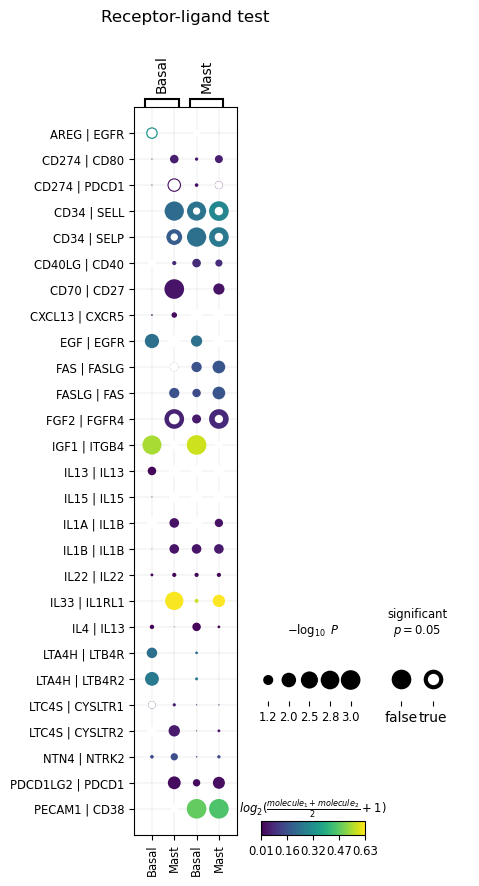

In [77]:
sq.pl.ligrec(res, source_groups=["Basal", 'Mast'], alpha=0.05)

In [79]:
# obj=basal_mast[basal_mast.obs['Group'].isin(['COPD'])]

# sp.pp.normalize_per_cell(obj)

# obj.raw = obj.copy()


# res = sq.gr.ligrec(obj, "subtype",
#                            fdr_method=None, copy=True,
#                            interactions_params={"resources": "CellPhoneDB"},
#                            threshold=0, seed=0, n_perms=10000, n_jobs=1)

# sq.pl.ligrec(res, source_groups=["Basal", 'Mast'], alpha=0.05)
res['pvalues']

cluster_1          Basal            Mast        
cluster_2          Basal    Mast   Basal    Mast
source   target                                 
EGF      EGFR       0.01  0.9948  0.0364    0.99
CD40LG   CD40     0.8332  0.4154   0.098  0.1668
CD70     CD27      0.963     0.0  0.9986   0.037
FAS      FASLG    0.9799  0.1048  0.0536  0.0201
FASLG    FAS      0.9799  0.0536  0.1048  0.0201
AREG     EGFR     0.0311  0.9943  0.4436  0.9689
CXCL13   CXCR5    0.7782  0.2763  0.3028  0.2218
PECAM1   CD38        1.0     1.0     0.0     0.0
FGF2     FGFR4       1.0     0.0   0.086     0.0
CD274    PDCD1    0.8737  0.0138  0.4856  0.1263
         CD80     0.8756  0.0999  0.5243  0.1244
IL33     IL1RL1   0.9768  0.0009  0.4456  0.0232
PDCD1LG2 PDCD1    0.9735  0.0188  0.1504  0.0265
CD34     SELL        1.0  0.0002  0.0003     0.0
         SELP        1.0  0.0048  0.0002     0.0
IGF1     ITGB4    0.0003     1.0     0.0  0.9997
IL13     IL13      0.102   0.898   0.898   0.898
IL15     IL15      0.876   0.124   0.124   0.124
IL1A     IL1B     0.8904  0.0673  0.7083  0.1096
IL1B     IL1B      0.931   0.069   0.069   0.069
IL22     IL22      0.584   0.416   0.416   0.416
IL4      IL13      0.392  0.9144  0.1034   0.608
LTA4H    LTB4R    0.0483  0.9604  0.6072  0.9517
         LTB4R2   0.0122  0.9938  0.5666  0.9878
NTN4     NTRK2     0.481  0.1572  0.8112   0.519
LTC4S    CYSLTR1  0.1436  0.5377  0.8615  0.8564
         CYSLTR2  0.4081  0.0343  0.8826  0.5919

/home/haider/miniconda3/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
100%|█████████████████████████████| 1000/1000 [00:01<00:00, 959.58permutation/s]


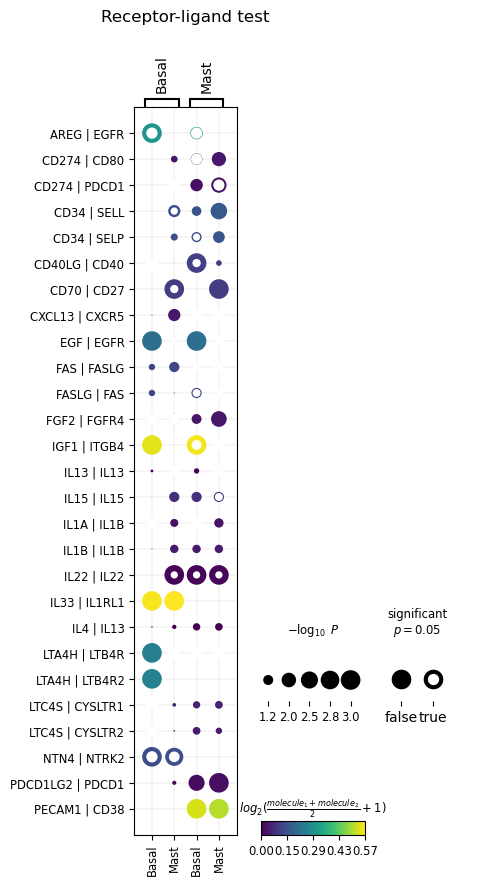

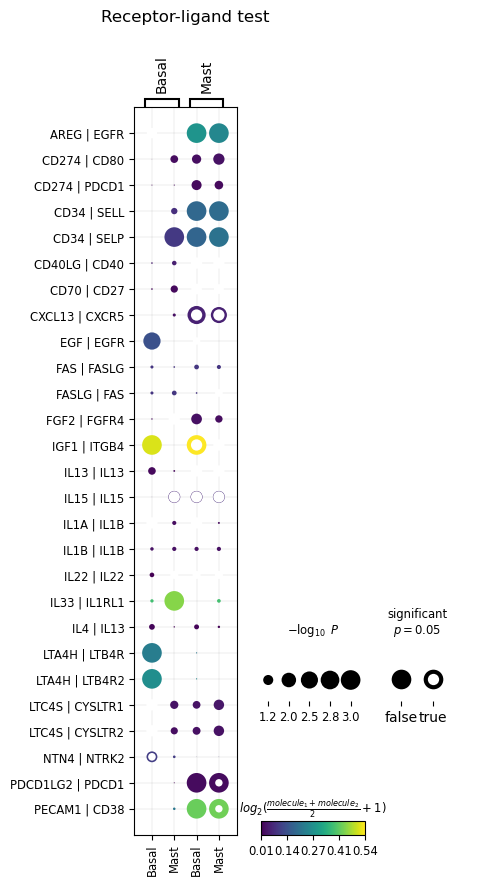

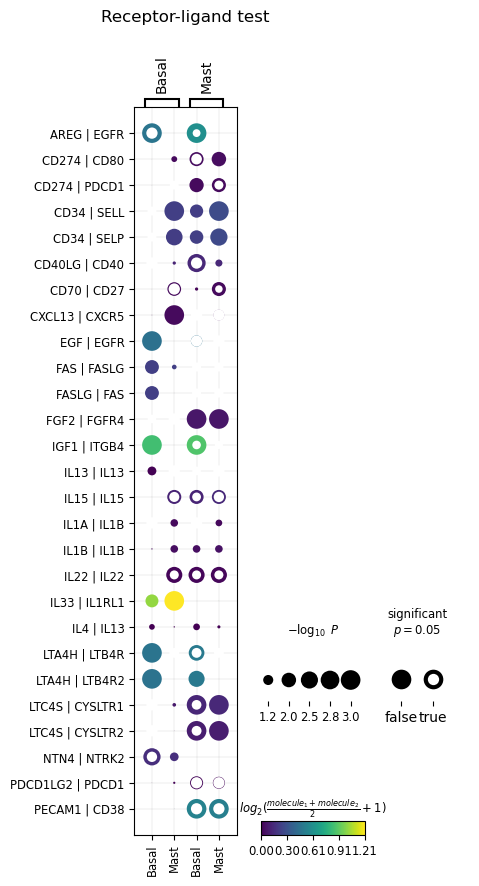

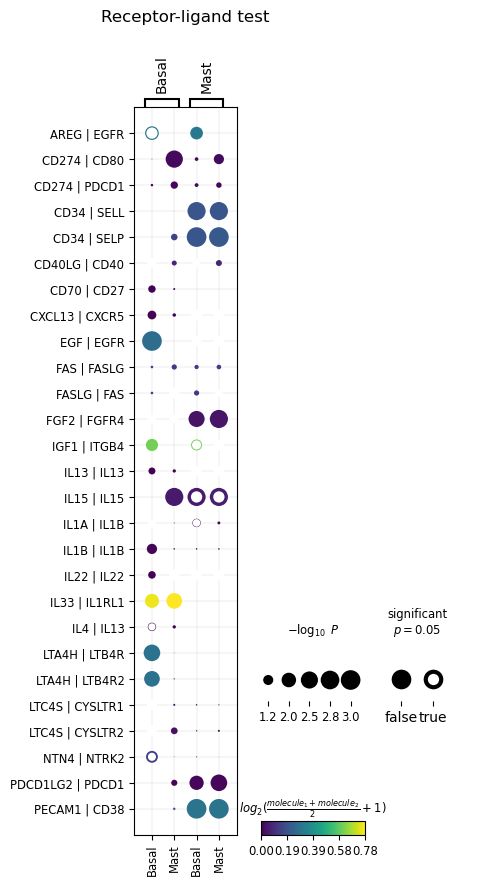

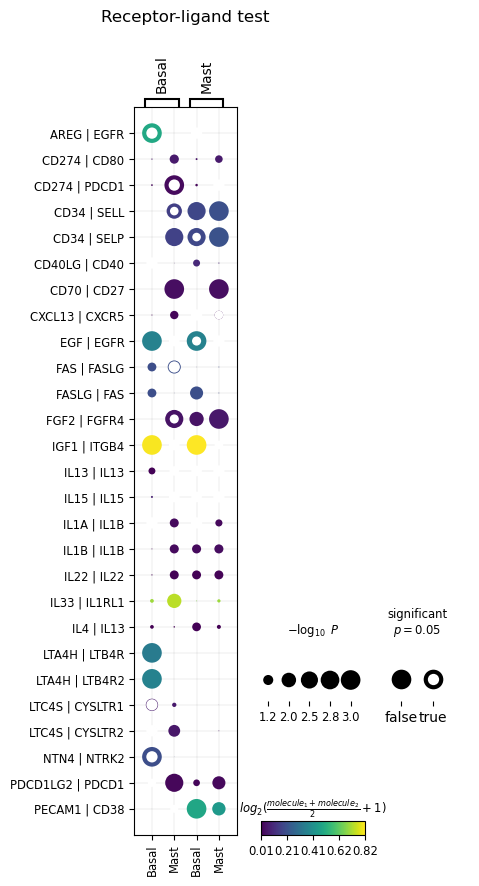

In [18]:


def receptor_ligand(disease_group):
    for i in disease_group:
        obj=basal_mast[basal_mast.obs['Group'].isin([i])]
        res = sq.gr.ligrec(obj, "subtype",
                           fdr_method=None, copy=True,use_raw=False,
                           interactions_params={"resources": "CellPhoneDB"},
                           threshold=0, seed=0, n_perms=1000, n_jobs=1)
        sq.pl.ligrec(res, source_groups=["Basal", 'Mast'],alpha=0.05),save='/home/haider/Squidpy_Spatial_analysis/Airway/Basal_Mast_RL/{}_RL.pdf'.format(i))
receptor_ligand(['CF', 'BOS', 'HC', 'Asthma', 'COPD'])
    

In [28]:
# final_obj = sp.read_h5ad('/home/haider/Squidpy_Spatial_analysis/final_merged')
# final_obj=final_obj[~final_obj.obs['ID'].isin(['MTS38D', 'MTS43D'])]
# HC_CF = final_obj[final_obj.obs['Group'].isin(['CF', 'HC'])]
# HC_CF_BB = HC_CF[HC_CF.obs['subtype'].isin(['Basal', 'BC'])]
HC_CF_GB = HC_CF[HC_CF.obs['subtype'].isin(['Basal', 'GB'])]


100%|██████████████████████████████| 1000/1000 [44:18<00:00,  2.66s/permutation]


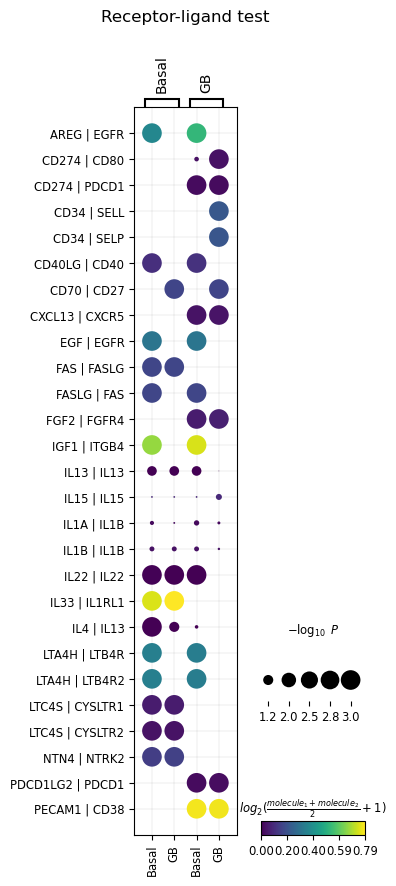

In [78]:
# res = sq.gr.ligrec(HC_CF_BB, "subtype",
#                    fdr_method=None, copy=True,use_raw=False,
#                    interactions_params={"resources": "CellPhoneDB"},
#                    threshold=0, seed=0, n_perms=1000, n_jobs=1)
# sq.pl.ligrec(res, source_groups=["Basal", 'BC'], alpha=None. save='/home/haider/Squidpy_Spatial_analysis/Complete_obj_Ligand_Receptor/HC_CF_Basal_BC_RL.pdf')

res = sq.gr.ligrec(HC_CF_GB, "subtype",
                   fdr_method=None, copy=True,use_raw=False,
                   interactions_params={"resources": "CellPhoneDB"},
                   threshold=0, seed=0, n_perms=1000, n_jobs=1)
sq.pl.ligrec(res, source_groups=["Basal", 'GB'], alpha=None, save='/home/haider/Squidpy_Spatial_analysis/Complete_obj_Ligand_Receptor/HC_CF_Basal_GB_RL.pdf')